# Исследование CNN

## 1. Импорт

In [1]:
import copy
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство: {device}")

Устройство: mps


## 2. Загрузка и подготовка данных

In [14]:
EPOCHS = 3
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
MAX_TRAIN_SAMPLES = None  # None is all set
MAX_TEST_SAMPLES = None   # None is all set
DATA_DIR = Path("data")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

mnist_train_full = datasets.MNIST(DATA_DIR, train=True, download=True, transform=transform)
mnist_test_full = datasets.MNIST(DATA_DIR, train=False, download=True, transform=transform)
fashion_train_full = datasets.FashionMNIST(DATA_DIR, train=True, download=True, transform=transform)
fashion_test_full = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=transform)


def limited(dataset, limit):
    if limit is None or limit >= len(dataset):
        return dataset
    return Subset(dataset, range(limit))


mnist_train = limited(mnist_train_full, MAX_TRAIN_SAMPLES)
mnist_test = limited(mnist_test_full, MAX_TEST_SAMPLES)
fashion_train = limited(fashion_train_full, MAX_TRAIN_SAMPLES)
fashion_test = limited(fashion_test_full, MAX_TEST_SAMPLES)


def make_loaders(dataset_train, dataset_test):
    return (
        DataLoader(dataset_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=0),
        DataLoader(dataset_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0),
    )


mnist_train_loader, mnist_test_loader = make_loaders(mnist_train, mnist_test)
fashion_train_loader, fashion_test_loader = make_loaders(fashion_train, fashion_test)
class_names = fashion_train_full.classes
print(f"MNIST: {len(mnist_train):,} train / {len(mnist_test):,} test")
print(f"FashionMNIST: {len(fashion_train):,} train / {len(fashion_test):,} test")

MNIST: 60,000 train / 10,000 test
FashionMNIST: 60,000 train / 10,000 test


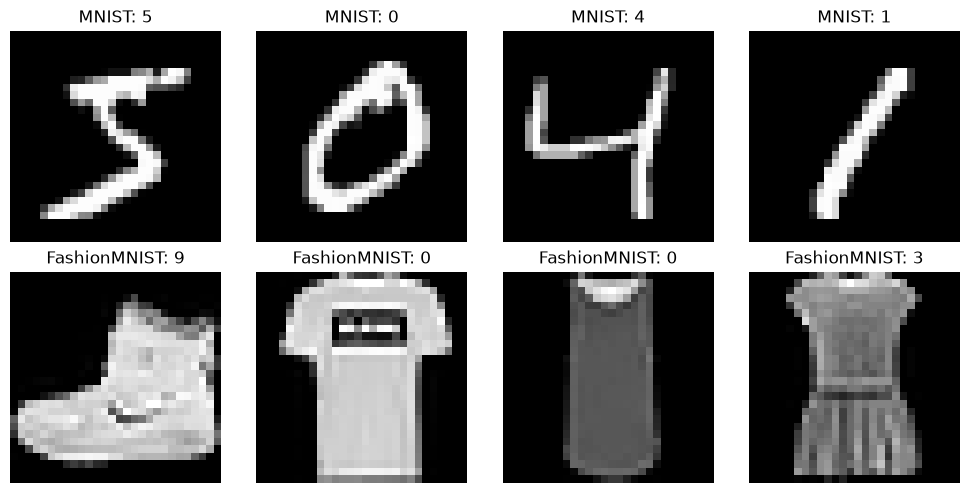

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for row, (dataset, title) in enumerate([
    (mnist_train, "MNIST"),
    (fashion_train, "FashionMNIST"),
]):
    for column in range(4):
        image, label = dataset[column]
        axes[row, column].imshow(image.squeeze(), cmap="gray")
        axes[row, column].set_title(f"{title}: {label}")
        axes[row, column].axis("off")
plt.tight_layout()
plt.show()

## 3. Импорт и инициализация CNN из внешнего файла

In [4]:
from cnn import CNNClassifier

model = CNNClassifier(num_classes=10).to(device)
print(model)
print(f"Параметров всего: {sum(p.numel() for p in model.parameters()):,}")

CNNClassifier(
  (backbone): CNNBackbone(
    (features): Sequential(
      (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (6): ReLU(inplace=True)
      (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
      (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (10): ReLU(inplace=True)
      (11): AdaptiveAvgPool2d(output_size=(1, 1))
      (12): Flatten(start_dim=1, end_dim=-1

In [5]:
criterion = nn.CrossEntropyLoss()


def evaluate(model, loader, collect_predictions=False):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    all_targets, all_predictions, all_probabilities = [], [], []
    with torch.inference_mode():
        for images, targets in loader:
            images, targets = images.to(device), targets.to(device)
            logits = model(images)
            total_loss += criterion(logits, targets).item() * targets.size(0)
            predictions = logits.argmax(dim=1)
            correct += (predictions == targets).sum().item()
            total += targets.size(0)
            if collect_predictions:
                all_targets.append(targets.cpu())
                all_predictions.append(predictions.cpu())
                all_probabilities.append(logits.softmax(dim=1).cpu())
    metrics = {"loss": total_loss / total, "accuracy": correct / total}
    if collect_predictions:
        return metrics, torch.cat(all_targets), torch.cat(all_predictions), torch.cat(all_probabilities)
    return metrics


def train_model(
    model, train_loader, test_loader, epochs=EPOCHS, lr=LEARNING_RATE, name="model",
    monitor_loader=None, monitor_head_state=None,
):
    if (monitor_loader is None) != (monitor_head_state is None):
        raise ValueError("Для мониторинга нужны и loader, и сохранённая голова")
    trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
    if not trainable:
        raise ValueError("В модели нет обучаемых параметров")
    optimizer = torch.optim.Adam(trainable, lr=lr)
    history = {"train_loss": [], "train_accuracy": [], "test_loss": [], "test_accuracy": []}
    if monitor_loader is not None:
        history["task1_test_loss"] = []
        history["task1_test_accuracy"] = []
    best_accuracy = -1.0
    best_state = None

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        correct = 0
        total = 0
        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * targets.size(0)
            correct += (logits.argmax(dim=1) == targets).sum().item()
            total += targets.size(0)

        train_metrics = {"loss": total_loss / total, "accuracy": correct / total}
        test_metrics = evaluate(model, test_loader)
        history["train_loss"].append(train_metrics["loss"])
        history["train_accuracy"].append(train_metrics["accuracy"])
        history["test_loss"].append(test_metrics["loss"])
        history["test_accuracy"].append(test_metrics["accuracy"])
        monitor_metrics = None
        if monitor_loader is not None:
            monitor_model = fresh_model(save_state(model.backbone), monitor_head_state)
            monitor_metrics = evaluate(monitor_model, monitor_loader)
            history["task1_test_loss"].append(monitor_metrics["loss"])
            history["task1_test_accuracy"].append(monitor_metrics["accuracy"])
        print(
            f"{name} | эпоха {epoch + 1}/{epochs} | "
            f"train loss={train_metrics['loss']:.4f}, acc={train_metrics['accuracy']:.3f} | "
            f"test loss={test_metrics['loss']:.4f}, acc={test_metrics['accuracy']:.3f}"
            + (f" | MNIST acc={monitor_metrics['accuracy']:.3f}" if monitor_metrics else "")
        )
        if test_metrics["accuracy"] > best_accuracy:
            best_accuracy = test_metrics["accuracy"]
            best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model, history, best_accuracy


def save_state(module):
    return {key: value.detach().cpu().clone() for key, value in module.state_dict().items()}


def fresh_model(backbone_state, head_state):
    new_model = CNNClassifier(num_classes=10)
    new_model.backbone.load_state_dict(backbone_state)
    new_model.head.load_state_dict(head_state)
    return new_model.to(device)


def score_tasks(model, include_mnist=True):
    scores = {"FashionMNIST": evaluate(model, fashion_test_loader)["accuracy"]}
    if include_mnist:
        scores["MNIST"] = evaluate(model, mnist_test_loader)["accuracy"]
    return scores

## 4. Обучение и оценка модели

In [6]:
checkpoint_dir = Path("checkpoints")
checkpoint_dir.mkdir(exist_ok=True)

head_fashion_seed_model = CNNClassifier(num_classes=10)
head_fashion_initial_state = save_state(head_fashion_seed_model.head)

mnist_model = CNNClassifier(num_classes=10).to(device)
mnist_model, history_mnist, best_mnist_accuracy = train_model(
    mnist_model, mnist_train_loader, mnist_test_loader, name="MNIST с нуля"
)
backbone_mnist_state = save_state(mnist_model.backbone)
head_mnist_state = save_state(mnist_model.head)

torch.save({
    "backbone_mnist": backbone_mnist_state,
    "head_mnist": head_mnist_state,
    "head_fashion_initial": head_fashion_initial_state,
}, checkpoint_dir / "initial_states.pt")

print(f"Лучшая accuracy MNIST: {best_mnist_accuracy:.4f}")
print("Сохранены backbone MNIST, обученная голова MNIST и случайная голова FashionMNIST.")

MNIST с нуля | эпоха 1/3 | train loss=0.4282, acc=0.912 | test loss=0.3619, acc=0.882
MNIST с нуля | эпоха 2/3 | train loss=0.0933, acc=0.975 | test loss=0.1147, acc=0.968
MNIST с нуля | эпоха 3/3 | train loss=0.0625, acc=0.983 | test loss=0.1114, acc=0.967
Лучшая accuracy MNIST: 0.9676
Сохранены backbone MNIST, обученная голова MNIST и случайная голова FashionMNIST.


In [7]:
# B. Перенос признаков: backbone MNIST заморожен, обучается только голова FashionMNIST.
model_frozen = fresh_model(backbone_mnist_state, head_fashion_initial_state)
model_frozen.freeze_backbone(True)
model_frozen, history_frozen, best_frozen_accuracy = train_model(
    model_frozen, fashion_train_loader, fashion_test_loader,
    name="Замороженный backbone",
    monitor_loader=mnist_test_loader, monitor_head_state=head_mnist_state,
)
state_frozen = {
    "backbone": save_state(model_frozen.backbone),
    "head": save_state(model_frozen.head),
}
scores_frozen = score_tasks(model_frozen)
print("После обучения только головы:", scores_frozen)

# C. Продолжаем обучение той же модели, размораживая общие свёрточные преобразования.
model_finetuned = fresh_model(state_frozen["backbone"], state_frozen["head"])
model_finetuned.freeze_backbone(False)
model_finetuned, history_finetune, best_finetune_accuracy = train_model(
    model_finetuned, fashion_train_loader, fashion_test_loader,
    lr=LEARNING_RATE / 10, name="Fine-tuning после заморозки",
    monitor_loader=mnist_test_loader, monitor_head_state=head_mnist_state,
)
state_finetuned = {
    "backbone": save_state(model_finetuned.backbone),
    "head": save_state(model_finetuned.head),
}
model_task1_after_finetune = fresh_model(state_finetuned["backbone"], head_mnist_state)
scores_finetune = {
    "FashionMNIST": evaluate(model_finetuned, fashion_test_loader)["accuracy"],
    "MNIST с исходной головой": evaluate(model_task1_after_finetune, mnist_test_loader)["accuracy"],
}
print("После fine-tuning:", scores_finetune)

history_transfer = {
    key: history_frozen[key] + history_finetune[key]
    for key in history_frozen
}
results = {
    "Fashion: frozen + fine-tuning": {
        "history": history_transfer, "model": model_finetuned,
        "accuracy": scores_finetune["FashionMNIST"],
    },
}

Замороженный backbone | эпоха 1/3 | train loss=1.3903, acc=0.559 | test loss=1.1228, acc=0.644 | MNIST acc=0.968
Замороженный backbone | эпоха 2/3 | train loss=1.0359, acc=0.668 | test loss=0.9804, acc=0.686 | MNIST acc=0.968
Замороженный backbone | эпоха 3/3 | train loss=0.9357, acc=0.694 | test loss=0.9112, acc=0.698 | MNIST acc=0.968
После обучения только головы: {'FashionMNIST': 0.6981, 'MNIST': 0.0917}
Fine-tuning после заморозки | эпоха 1/3 | train loss=0.9491, acc=0.713 | test loss=0.6329, acc=0.790 | MNIST acc=0.558
Fine-tuning после заморозки | эпоха 2/3 | train loss=0.5483, acc=0.817 | test loss=0.5036, acc=0.830 | MNIST acc=0.578
Fine-tuning после заморозки | эпоха 3/3 | train loss=0.4623, acc=0.845 | test loss=0.4455, acc=0.849 | MNIST acc=0.528
После fine-tuning: {'FashionMNIST': 0.8492, 'MNIST с исходной головой': 0.5281}


In [8]:
# D. Те же сохранённые параметры, но backbone разморожен с самого начала обучения FashionMNIST.
initial_states = torch.load(checkpoint_dir / "initial_states.pt", map_location="cpu", weights_only=True)
model_unfrozen = fresh_model(
    initial_states["backbone_mnist"], initial_states["head_fashion_initial"]
)
model_unfrozen.freeze_backbone(False)
model_unfrozen, history_unfrozen, best_unfrozen_accuracy = train_model(
    model_unfrozen, fashion_train_loader, fashion_test_loader,
    name="Сохранённые веса, сразу разморожены",
    monitor_loader=mnist_test_loader, monitor_head_state=head_mnist_state,
)
state_unfrozen = {
    "backbone": save_state(model_unfrozen.backbone),
    "head": save_state(model_unfrozen.head),
}
model_task1_after_unfrozen = fresh_model(state_unfrozen["backbone"], head_mnist_state)
scores_unfrozen = {
    "FashionMNIST": evaluate(model_unfrozen, fashion_test_loader)["accuracy"],
    "MNIST с исходной головой": evaluate(model_task1_after_unfrozen, mnist_test_loader)["accuracy"],
}
print("После обучения без заморозки:", scores_unfrozen)
results["Fashion: сохранённые веса, сразу разморожены"] = {
    "history": history_unfrozen, "model": model_unfrozen,
    "accuracy": scores_unfrozen["FashionMNIST"],
}

# E. Контроль: случайная сеть, первые два свёрточных блока заморожены.
model_random = CNNClassifier(num_classes=10).to(device)
feature_layers = list(model_random.backbone.features.children())
for layer in feature_layers[:8]:
    for parameter in layer.parameters():
        parameter.requires_grad = False
model_random, history_random, best_random_accuracy = train_model(
    model_random, fashion_train_loader, fashion_test_loader,
    name="Случайная CNN, заморожены первые два блока"
)

scores_random = {"FashionMNIST": evaluate(model_random, fashion_test_loader)["accuracy"]}
print("Контрольный запуск:", scores_random)
results["Fashion: случайные веса, частичная заморозка"] = {
    "history": history_random, "model": model_random,
    "accuracy": scores_random["FashionMNIST"],
}

# Сохраняем checkpoint каждого этапа отдельно для воспроизведения экспериментов.
torch.save({
    "frozen_head_only": {"backbone": backbone_mnist_state, "head": state_frozen["head"]},
    "finetuned": state_finetuned,
    "unfrozen_from_checkpoint": state_unfrozen,
    "random_partial": {
        "backbone": save_state(model_random.backbone), "head": save_state(model_random.head)
    },
}, checkpoint_dir / "trained_models.pt")

Сохранённые веса, сразу разморожены | эпоха 1/3 | train loss=0.5912, acc=0.807 | test loss=0.5123, acc=0.813 | MNIST acc=0.147
Сохранённые веса, сразу разморожены | эпоха 2/3 | train loss=0.3588, acc=0.873 | test loss=0.5369, acc=0.800 | MNIST acc=0.204
Сохранённые веса, сразу разморожены | эпоха 3/3 | train loss=0.3135, acc=0.889 | test loss=0.3603, acc=0.874 | MNIST acc=0.156
После обучения без заморозки: {'FashionMNIST': 0.8736, 'MNIST с исходной головой': 0.1558}
Случайная CNN, заморожены первые два блока | эпоха 1/3 | train loss=0.7968, acc=0.751 | test loss=0.8300, acc=0.725
Случайная CNN, заморожены первые два блока | эпоха 2/3 | train loss=0.5074, acc=0.823 | test loss=0.6342, acc=0.768
Случайная CNN, заморожены первые два блока | эпоха 3/3 | train loss=0.4494, acc=0.840 | test loss=0.5043, acc=0.824
Контрольный запуск: {'FashionMNIST': 0.8241}


## 5. Оценка точности модели

In [9]:
evaluation_rows = [
    {"Задача": "MNIST", "Стратегия": "Обучение с нуля", "Test accuracy": best_mnist_accuracy,
     "MNIST после переноса": best_mnist_accuracy},
    {"Задача": "FashionMNIST", "Стратегия": "Только голова, backbone заморожен",
     "Test accuracy": best_frozen_accuracy,
     "MNIST после переноса": evaluate(fresh_model(backbone_mnist_state, head_mnist_state), mnist_test_loader)["accuracy"]},
    {"Задача": "FashionMNIST", "Стратегия": "Замороженная голова + fine-tuning",
     "Test accuracy": scores_finetune["FashionMNIST"],
     "MNIST после переноса": scores_finetune["MNIST с исходной головой"]},
    {"Задача": "FashionMNIST", "Стратегия": "Сохранённые веса, сразу разморожены",
     "Test accuracy": scores_unfrozen["FashionMNIST"],
     "MNIST после переноса": scores_unfrozen["MNIST с исходной головой"]},
    {"Задача": "FashionMNIST", "Стратегия": "Случайные веса, первые блоки заморожены",
     "Test accuracy": scores_random["FashionMNIST"],
     "MNIST после переноса": np.nan},
]
results_table = pd.DataFrame(evaluation_rows)
results_table.sort_values(["Задача", "Test accuracy"], ascending=[True, False])

,Задача,Стратегия,Test accuracy,MNIST после переноса
3,FashionMNIST,"Сохранённые веса, сразу разморожены",0.8736,0.1558
2,FashionMNIST,Замороженная голова + fine-tuning,0.8492,0.5281
4,FashionMNIST,"Случайные веса, первые блоки заморожены",0.8241,NaN
1,FashionMNIST,"Только голова, backbone заморожен",0.6981,0.9676
0,MNIST,Обучение с нуля,0.9676,0.9676


## 6. Визуализация результатов

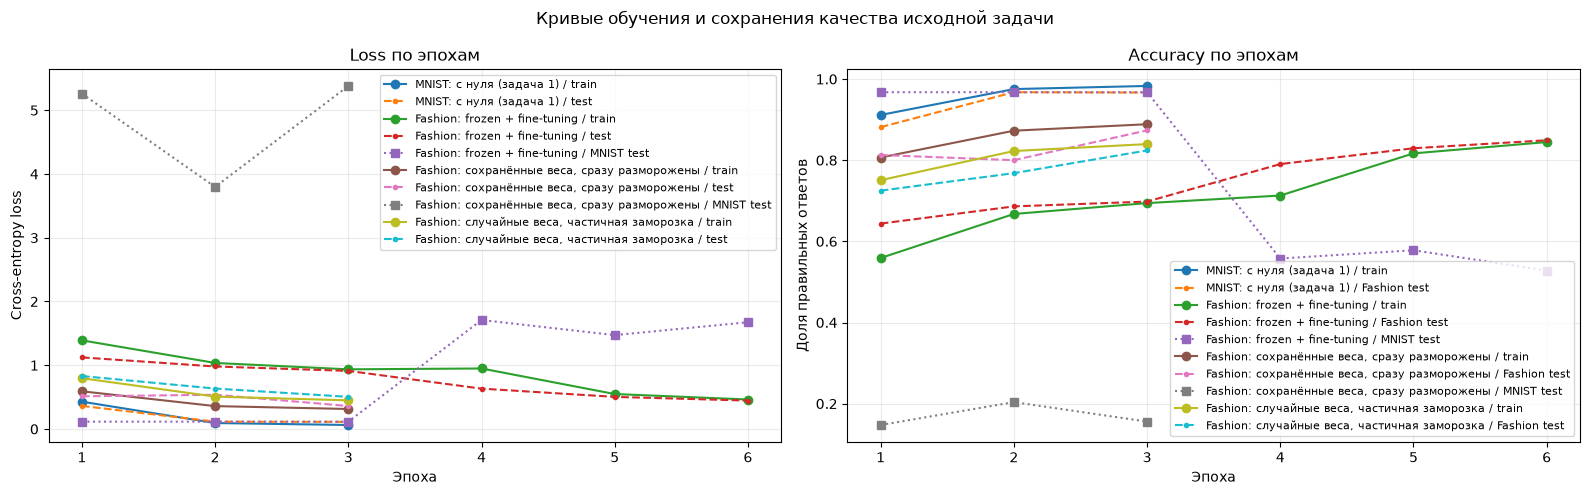

MNIST baseline и FashionMNIST решают разные задачи; сравнивайте кривые внутри каждой задачи.


In [10]:
histories_for_plot = {"MNIST: с нуля (задача 1)": history_mnist}
histories_for_plot.update({name: entry["history"] for name, entry in results.items()})

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for name, history in histories_for_plot.items():
    epochs = np.arange(1, len(history["train_loss"]) + 1)
    axes[0].plot(epochs, history["train_loss"], marker="o", label=f"{name} / train")
    axes[0].plot(epochs, history["test_loss"], marker=".", linestyle="--", label=f"{name} / test")
    axes[1].plot(epochs, history["train_accuracy"], marker="o", label=f"{name} / train")
    axes[1].plot(epochs, history["test_accuracy"], marker=".", linestyle="--", label=f"{name} / Fashion test")
    if "task1_test_accuracy" in history:
        axes[1].plot(
            epochs, history["task1_test_accuracy"], marker="s", linestyle=":",
            label=f"{name} / MNIST test",
        )
        axes[0].plot(
            epochs, history["task1_test_loss"], marker="s", linestyle=":",
            label=f"{name} / MNIST test",
        )
axes[0].set(title="Loss по эпохам", xlabel="Эпоха", ylabel="Cross-entropy loss")
axes[1].set(title="Accuracy по эпохам", xlabel="Эпоха", ylabel="Доля правильных ответов")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize=8)
fig.suptitle("Кривые обучения и сохранения качества исходной задачи")
plt.tight_layout()
plt.show()

In [11]:
fashion_results = {
    name: entry for name, entry in results.items()
    if name != "MNIST: обучение с нуля"
}
best_strategy = max(fashion_results, key=lambda name: fashion_results[name]["accuracy"])
best_model = fashion_results[best_strategy]["model"]
print(f"Лучшая FashionMNIST-модель: {best_strategy}")
print(f"Test accuracy: {fashion_results[best_strategy]['accuracy']:.4f}")
results_table.sort_values(["Задача", "Test accuracy"], ascending=[True, False])

Лучшая FashionMNIST-модель: Fashion: сохранённые веса, сразу разморожены
Test accuracy: 0.8736


,Задача,Стратегия,Test accuracy,MNIST после переноса
3,FashionMNIST,"Сохранённые веса, сразу разморожены",0.8736,0.1558
2,FashionMNIST,Замороженная голова + fine-tuning,0.8492,0.5281
4,FashionMNIST,"Случайные веса, первые блоки заморожены",0.8241,NaN
1,FashionMNIST,"Только голова, backbone заморожен",0.6981,0.9676
0,MNIST,Обучение с нуля,0.9676,0.9676


              precision    recall  f1-score   support

 T-shirt/top      0.799     0.872     0.834      1000
     Trouser      0.995     0.963     0.979      1000
    Pullover      0.843     0.809     0.826      1000
       Dress      0.824     0.926     0.872      1000
        Coat      0.732     0.862     0.792      1000
      Sandal      0.947     0.962     0.954      1000
       Shirt      0.776     0.565     0.654      1000
     Sneaker      0.871     0.986     0.925      1000
         Bag      0.996     0.914     0.953      1000
  Ankle boot      0.990     0.877     0.930      1000

    accuracy                          0.874     10000
   macro avg      0.877     0.874     0.872     10000
weighted avg      0.877     0.874     0.872     10000



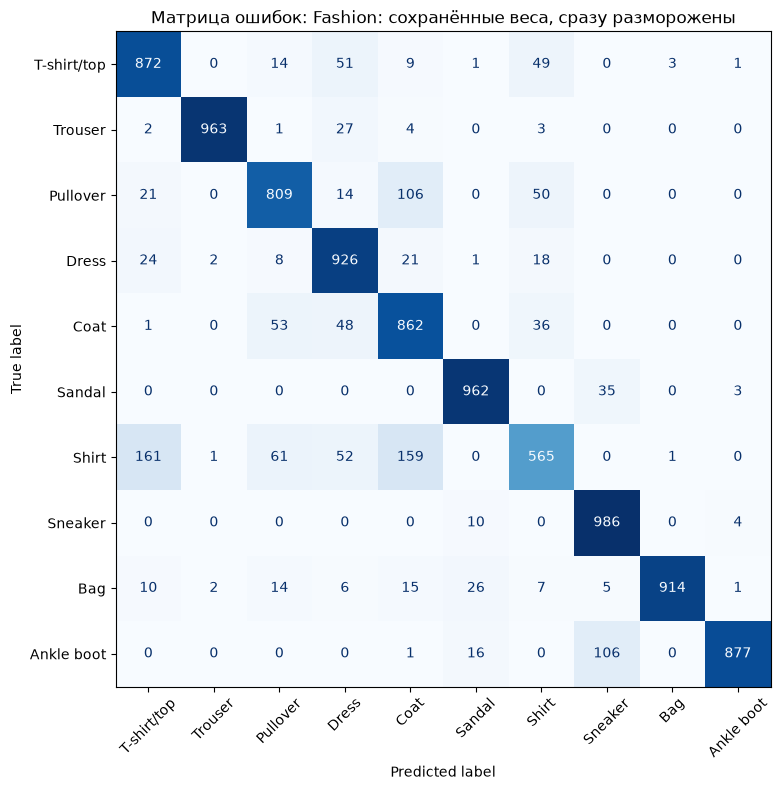

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix

metrics, y_true, y_pred, probabilities = evaluate(
    best_model, fashion_test_loader, collect_predictions=True
)
class_ids = np.arange(10)
print(classification_report(
    y_true.numpy(), y_pred.numpy(), labels=class_ids,
    target_names=class_names, digits=3, zero_division=0
))

matrix = confusion_matrix(y_true.numpy(), y_pred.numpy(), labels=class_ids)
fig, axis = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(matrix, display_labels=class_names).plot(
    ax=axis, xticks_rotation=45, cmap="Blues", colorbar=False
)
axis.set_title(f"Матрица ошибок: {best_strategy}")
plt.tight_layout()
plt.show()

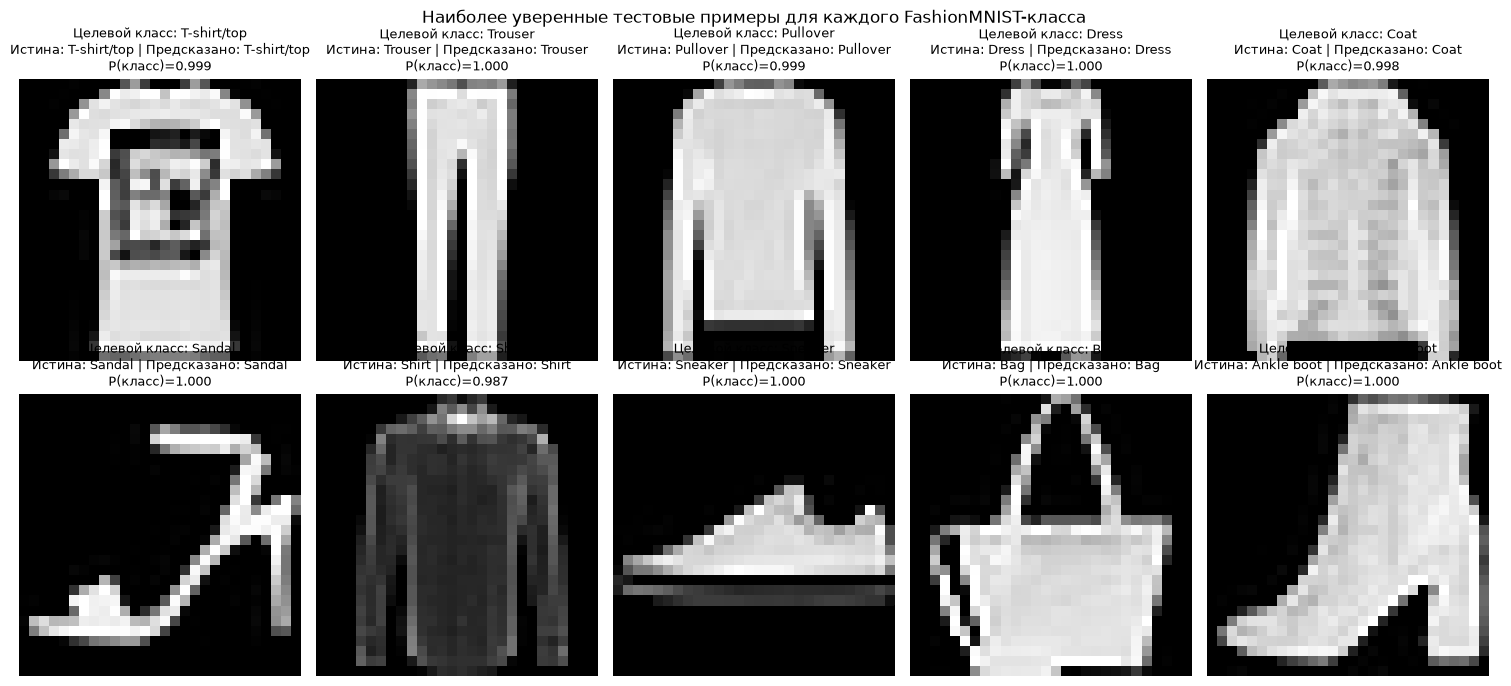

In [13]:
representative_indices = probabilities.argmax(dim=0).tolist()
fig, axes = plt.subplots(2, 5, figsize=(15, 7))
for class_id, axis in enumerate(axes.flat):
    sample_index = representative_indices[class_id]
    image, true_label = fashion_test[sample_index]
    predicted_label = int(y_pred[sample_index])
    confidence = float(probabilities[sample_index, class_id])
    axis.imshow(image.squeeze(), cmap="gray")
    axis.set_title(
        f"Целевой класс: {class_names[class_id]}\n"
        f"Истина: {class_names[true_label]} | Предсказано: {class_names[predicted_label]}\n"
        f"P(класс)={confidence:.3f}", fontsize=9
    )
    axis.axis("off")
fig.suptitle("Наиболее уверенные тестовые примеры для каждого FashionMNIST-класса")
plt.tight_layout()
plt.show()